# 01 - EDA & Data Wrangling (CardioAgent-Ops)

Pipeline : inventaire -> nettoyage -> split par enregistrement -> prétraitement (2000 Hz, filtrage, normalisation) -> segmentation -> features (MFCC, ZCR, spectrogramme Mel) -> rééquilibrage (train uniquement) -> sauvegarde.

Structure attendue : `ourdataset/train/normal/*.wav` et `ourdataset/train/abnormal/*.wav`.

Dépendances : `pip install librosa soundfile pandas numpy scipy scikit-learn matplotlib`

In [1]:
import re, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, soundfile as sf
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# ---- Paramètres ----
TARGET_SR = 2000        # Hz (imposé par le sujet)
SEG_SEC   = 5           # 2 ou 5 secondes
HOP_SEC   = 2.5         # pas de fenêtre glissante (50 % de chevauchement)
MIN_DUR   = 1.0         # durée minimale d'un enregistrement (s)
N_MFCC    = 20
N_FFT, HOP, N_MELS = 512, 64, 40

ROOT = Path("ourdataset/train")
if not ROOT.exists():
    ROOT = Path("../ourdataset/train")
assert ROOT.exists(), "Dossier ourdataset/train introuvable : lance le notebook depuis la racine du projet"
OUT = ROOT.parent / "processed"
OUT.mkdir(exist_ok=True)

LABELS = {"normal": 0, "abnormal": 1}   # 1 = classe pathologique (celle dont on maximise le Recall)

## 1. Inventaire des fichiers

In [2]:
rows = []
for cls, lab in LABELS.items():
    for p in sorted((ROOT / cls).glob("*.wav")):
        try:
            info = sf.info(str(p))
            rows.append(dict(path=str(p), file=p.name, label=lab, label_name=cls,
                             sr=info.samplerate, dur=info.duration,
                             channels=info.channels, error=None))
        except Exception as e:
            rows.append(dict(path=str(p), file=p.name, label=lab, label_name=cls,
                             sr=np.nan, dur=np.nan, channels=np.nan, error=str(e)))
df = pd.DataFrame(rows)

def guess_source(name):
    # Heuristique : PhysioNet/CinC 2016 -> a0001.wav ... f0xxx.wav ; le reste est supposé PASCAL.
    # A vérifier/adapter selon tes vrais noms de fichiers.
    return "physionet" if re.match(r"^[a-f]\d{4}", name.lower()) else "pascal"
df["source"] = df["file"].map(guess_source)

print(f"{len(df)} fichiers, {df['error'].notna().sum()} illisibles")
print(df.groupby("label_name").agg(n=("file", "count"), dur_moy=("dur", "mean"),
                                   dur_min=("dur", "min"), dur_max=("dur", "max")))
print(pd.crosstab(df["source"], df["label_name"]))
print(df["sr"].value_counts())

3784 fichiers, 0 illisibles
               n    dur_moy  dur_min   dur_max
label_name                                    
abnormal     858  21.451512  0.85675  121.9985
normal      2926  19.818975  0.76325  101.6730
label_name  abnormal  normal
source                      
pascal           193     351
physionet        665    2575
sr
2000     3240
4000      461
44100      83
Name: count, dtype: int64


## 2. Visualisations exploratoires

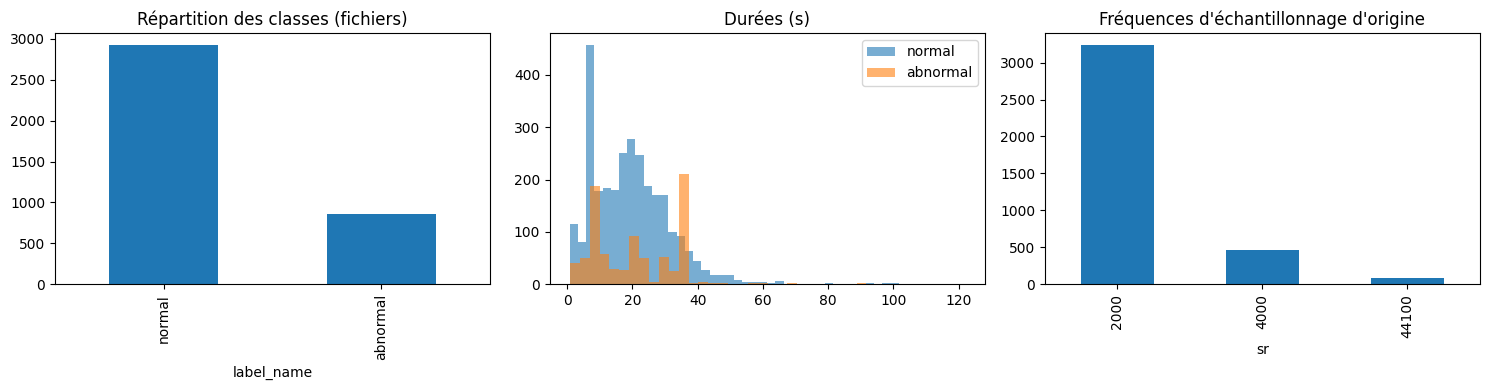

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["label_name"].value_counts().plot.bar(ax=ax[0], title="Répartition des classes (fichiers)")
for cls in LABELS:
    ax[1].hist(df.loc[df.label_name == cls, "dur"].dropna(), bins=40, alpha=.6, label=cls)
ax[1].set_title("Durées (s)"); ax[1].legend()
df["sr"].value_counts().plot.bar(ax=ax[2], title="Fréquences d'échantillonnage d'origine")
plt.tight_layout(); plt.show()

## 3. Nettoyage : fichiers illisibles, trop courts, doublons, conflits de label

In [4]:
n0 = len(df)
df = df[df["error"].isna()].copy()
df = df[df["dur"] >= MIN_DUR].copy()
df["hash"] = df["path"].map(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())

# même contenu dans normal ET abnormal -> label douteux, on supprime
conflict = df.groupby("hash")["label"].nunique()
conflict_hashes = conflict[conflict > 1].index
df = df[~df["hash"].isin(conflict_hashes)]
# doublons exacts
df = df.drop_duplicates(subset="hash", keep="first").reset_index(drop=True)
print(f"{n0} -> {len(df)} fichiers après nettoyage ({len(conflict_hashes)} conflits de label)")
print(df["label_name"].value_counts())

3784 -> 3781 fichiers après nettoyage (0 conflits de label)
label_name
normal      2925
abnormal     856
Name: count, dtype: int64


## 4. Split train / val / test **par enregistrement**

Le split est fait **avant** la segmentation : tous les segments d'un même fichier restent dans le même sous-ensemble (sinon fuite de données).
Si tu disposes d'un identifiant patient (ex. métadonnées PhysioNet), remplace `train_test_split` par `GroupShuffleSplit` avec ce groupe.

In [5]:
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=RANDOM_STATE)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=RANDOM_STATE)
df["split"] = "train"
df.loc[df["path"].isin(val_df["path"]), "split"] = "val"
df.loc[df["path"].isin(test_df["path"]), "split"] = "test"
print(pd.crosstab(df["split"], df["label_name"]))

label_name  abnormal  normal
split                       
test             129     439
train            599    2047
val              128     439


## 5. Prétraitement du signal : 2000 Hz, filtre passe-bande 25-400 Hz, normalisation, segmentation

In [6]:
SOS = butter(4, [25, 400], btype="band", fs=TARGET_SR, output="sos")
SEG_LEN, HOP_LEN = int(SEG_SEC * TARGET_SR), int(HOP_SEC * TARGET_SR)

def load_clean(path):
    y, _ = librosa.load(path, sr=TARGET_SR, mono=True)   # rééchantillonnage à 2000 Hz
    if y.size == 0 or np.max(np.abs(y)) < 1e-6:          # signal vide / silence total
        return None
    y = y - np.mean(y)
    y = sosfiltfilt(SOS, y)                              # bande utile du PCG
    y = y / (np.max(np.abs(y)) + 1e-9)                   # normalisation d'amplitude [-1, 1]
    return y.astype(np.float32)

MAX_SEG_PER_FILE = 10

def segment(y):
    if len(y) < SEG_LEN:
        return [np.resize(y, SEG_LEN)]
    starts = np.arange(0, len(y) - SEG_LEN + 1, HOP_LEN)
    if len(starts) > MAX_SEG_PER_FILE:       # on garde des fenêtres réparties sur tout l'enregistrement
        idx = np.linspace(0, len(starts) - 1, MAX_SEG_PER_FILE).round().astype(int)
        starts = starts[idx]
    return [y[i:i + SEG_LEN] for i in starts]

## 6. Extraction des caractéristiques (MFCC, ZCR, centroïde, RMS + spectrogramme Mel)

In [7]:
def features_1d(s):
    mfcc = librosa.feature.mfcc(y=s, sr=TARGET_SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                                hop_length=HOP, n_mels=N_MELS)
    zcr  = librosa.feature.zero_crossing_rate(s, frame_length=N_FFT, hop_length=HOP)
    cent = librosa.feature.spectral_centroid(y=s, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP)
    rms  = librosa.feature.rms(y=s, frame_length=N_FFT, hop_length=HOP)
    parts = [mfcc.mean(1), mfcc.std(1)]
    for m in (zcr, cent, rms):
        parts += [np.array([m.mean()]), np.array([m.std()])]
    return np.concatenate(parts).astype(np.float32)

def mel_db(s):
    m = librosa.feature.melspectrogram(y=s, sr=TARGET_SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    return librosa.power_to_db(m, ref=np.max).astype(np.float16)

feat_names = ([f"mfcc{i}_mean" for i in range(N_MFCC)] + [f"mfcc{i}_std" for i in range(N_MFCC)] +
              ["zcr_mean", "zcr_std", "centroid_mean", "centroid_std", "rms_mean", "rms_std"])

X_feat, X_mel, y_all, split_all, file_all = [], [], [], [], []
skipped = []
for r in df.itertuples():
    sig = load_clean(r.path)
    if sig is None:
        skipped.append(r.file); continue
    for s in segment(sig):
        X_feat.append(features_1d(s)); X_mel.append(mel_db(s))
        y_all.append(r.label); split_all.append(r.split); file_all.append(r.file)

X_feat = np.stack(X_feat); X_mel = np.stack(X_mel)[..., None]   # (N, n_mels, frames, 1)
y_all = np.array(y_all); split_all = np.array(split_all); file_all = np.array(file_all)
print("fichiers ignorés (silence) :", len(skipped))
print("X_feat", X_feat.shape, "| X_mel", X_mel.shape)
print(pd.crosstab(split_all, y_all))

fichiers ignorés (silence) : 0
X_feat (22126, 46) | X_mel (22126, 40, 157, 1)
col_0      0     1
row_0             
test    2568   862
train  11872  3484
val     2531   809


## 7. Visualisation : forme d'onde et spectrogramme (normal vs anormal)

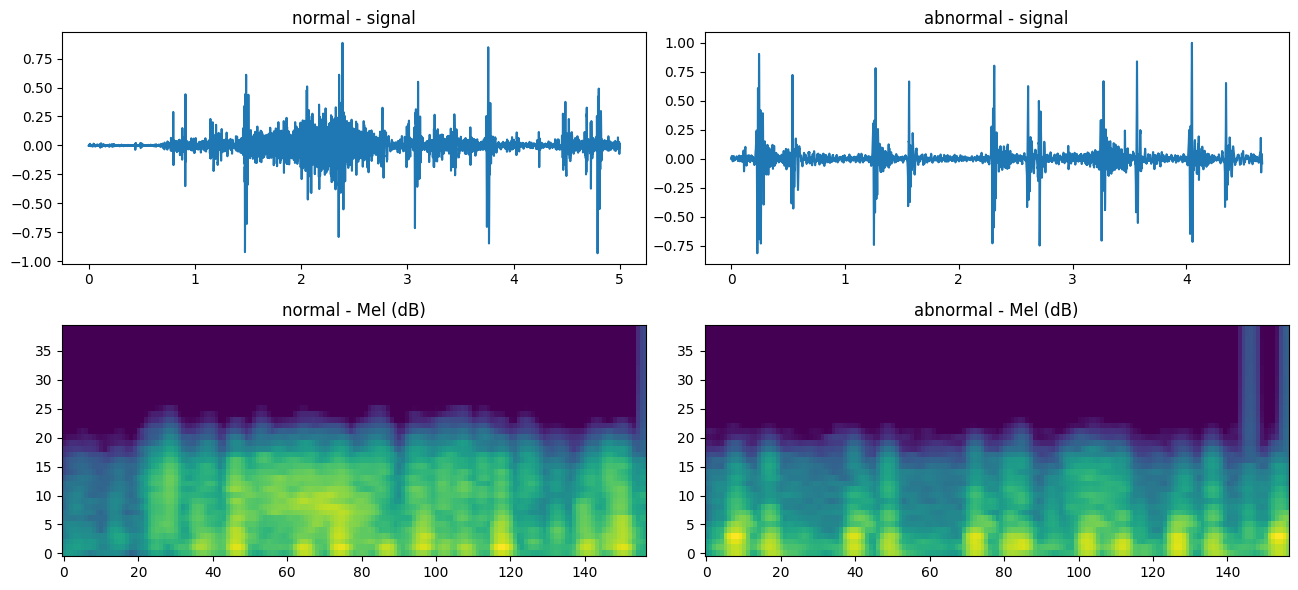

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for j, (cls, lab) in enumerate(LABELS.items()):
    i = np.where(y_all == lab)[0][0]
    sig = load_clean(df.loc[df["file"] == file_all[i], "path"].iloc[0])[:SEG_LEN]
    ax[0, j].plot(np.arange(len(sig)) / TARGET_SR, sig); ax[0, j].set_title(f"{cls} - signal")
    ax[1, j].imshow(X_mel[i, ..., 0].astype(np.float32), aspect="auto", origin="lower")
    ax[1, j].set_title(f"{cls} - Mel (dB)")
plt.tight_layout(); plt.show()

## 8. Rééquilibrage (train uniquement)

Les ensembles `val` et `test` ne sont **jamais** rééquilibrés : ils doivent refléter la distribution réelle.
On fournit deux leviers pour l'entraînement : des poids de classe et un index de suréchantillonnage de la classe minoritaire.

poids de classe : {0: 0.6467318059299192, 1: 2.203788748564868}
train avant : [11872  3484] | après suréchantillonnage : [11872 11872]


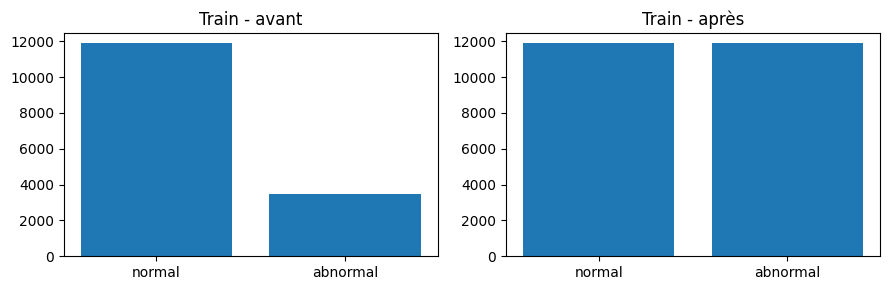

In [9]:
idx_tr = np.where(split_all == "train")[0]
y_tr = y_all[idx_tr]
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr)
class_weights = {0: float(cw[0]), 1: float(cw[1])}
print("poids de classe :", class_weights)

counts = np.bincount(y_tr, minlength=2)
maj = int(np.argmax(counts)); mino = 1 - maj
mino_idx = idx_tr[y_tr == mino]
extra = rng.choice(mino_idx, size=counts[maj] - counts[mino], replace=True)
train_oversampled_idx = np.concatenate([idx_tr, extra])
rng.shuffle(train_oversampled_idx)
print("train avant :", counts, "| après suréchantillonnage :", np.bincount(y_all[train_oversampled_idx]))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(["normal", "abnormal"], counts); ax[0].set_title("Train - avant")
ax[1].bar(["normal", "abnormal"], np.bincount(y_all[train_oversampled_idx])); ax[1].set_title("Train - après")
plt.tight_layout(); plt.show()

## 9. Sauvegarde (à ne pas commiter : `ourdataset/` est dans le `.gitignore`)

In [10]:
np.savez_compressed(OUT / "dataset_2000hz.npz",
                    X_feat=X_feat, X_mel=X_mel, y=y_all, split=split_all, recordings=file_all,
                    train_oversampled_idx=train_oversampled_idx,
                    feat_names=np.array(feat_names))
df.drop(columns=["error"]).to_csv(OUT / "metadata_clean.csv", index=False)
pd.Series(class_weights).to_json(OUT / "class_weights.json")
print("Sauvegardé dans", OUT.resolve())

Sauvegardé dans C:\Users\Admin\Desktop\Data Mining\ourdataset\processed
